In [15]:
import mne
from pathlib import Path
import numpy as np
import tqdm
import matplotlib as plt

In [26]:
DATA_FOLDER1 = Path("DATA/posterior")
DATA_FOLDER2 = Path("DATA/frontal")
EPOCH_FILES1 = sorted(DATA_FOLDER1.glob("*-epo.fif"))
EPOCH_FILES2 = sorted(DATA_FOLDER2.glob("*-epo.fif"))

In [27]:


if not EPOCH_FILES1:
    raise FileNotFoundError(f"No *-epo.fif files in {DATA_FOLDER1}")

if not EPOCH_FILES2:
    raise FileNotFoundError(f"No *-epo.fif files in {DATA_FOLDER2}")

# Load the first participant/file from each folder
file_path_1 = EPOCH_FILES1[0]
file_path_2 = EPOCH_FILES2[0]

post_epochs = mne.read_epochs(file_path_1, preload=True)
front_epochs = mne.read_epochs(file_path_2, preload=True)


def inspect_epochs(epochs, file_path, label):
    print(f"\n===== {label.upper()} =====")
    print(f"File: {file_path}")
    print(epochs)
    print(f"Number of epochs: {len(epochs)}")
    print(f"Sampling frequency: {epochs.info['sfreq']} Hz")
    print(
        f"Time range: {epochs.times[0]:.3f} to "
        f"{epochs.times[-1]:.3f} seconds"
    )
    print(f"Events: {epochs.event_id}")
    print(f"Bad channels: {epochs.info['bads']}")
    print(f"EEG channels: {len(epochs.copy().pick('eeg').ch_names)}")


inspect_epochs(post_epochs, file_path_1, "Posterior")
inspect_epochs(front_epochs, file_path_2, "Frontal")


Reading /Users/Emila/Desktop/SONATA21/IAF_WPR/DATA/posterior/HP1505_M_23_preprocessed-epo.fif ...
    Found the data of interest:
        t =     200.20 ...    1999.02 ms
        0 CTF compensation matrices available
Not setting metadata
66 matching events found
No baseline correction applied
0 projection items activated
Reading /Users/Emila/Desktop/SONATA21/IAF_WPR/DATA/frontal/HP1505_M_23_preprocessed-epo.fif ...
    Found the data of interest:
        t =     200.20 ...    1999.02 ms
        0 CTF compensation matrices available
Not setting metadata
65 matching events found
No baseline correction applied
0 projection items activated

===== POSTERIOR =====
File: DATA/posterior/HP1505_M_23_preprocessed-epo.fif
<EpochsFIF | 66 events (all good), 0.2 – 1.999 s (baseline off), ~4.7 MiB, data loaded,
 'experiment_mask_2_-1': 1
 'experiment_mask_2_1': 14
 'experiment_mask_3_0': 1
 'experiment_mask_3_1': 14
 'experiment_mask_4_1': 12
 'experiment_mask_5_0': 0
 'experiment_mask_5_1': 11
 'ex

Effective window size : 1.800 (s)
Effective window size : 1.800 (s)
Posterior PSD
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


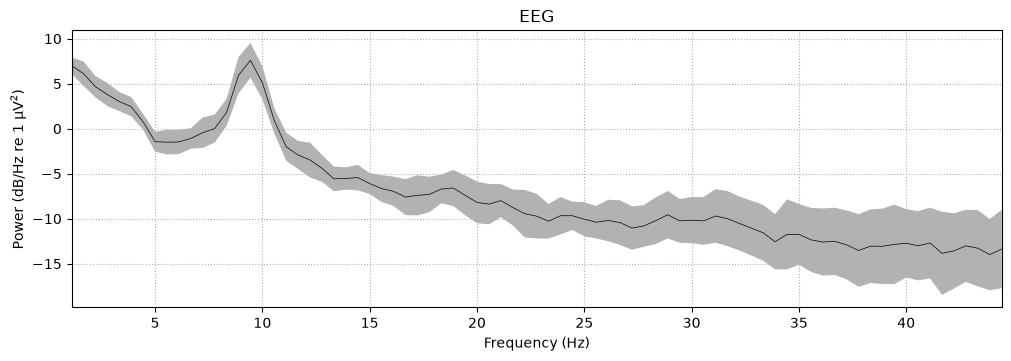

Frontal PSD
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


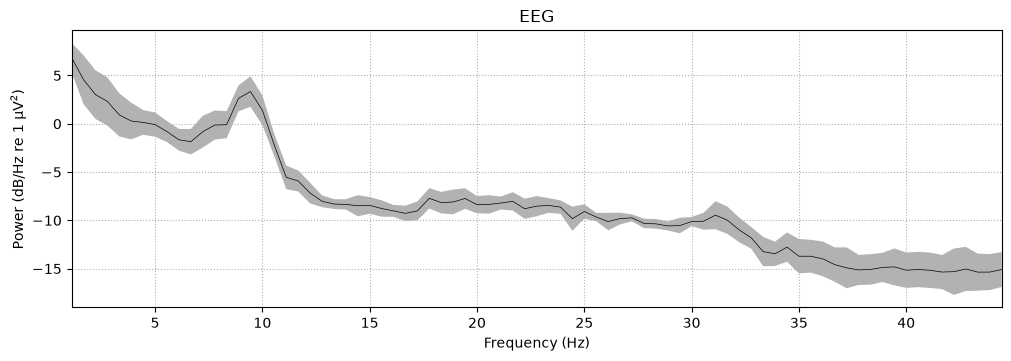

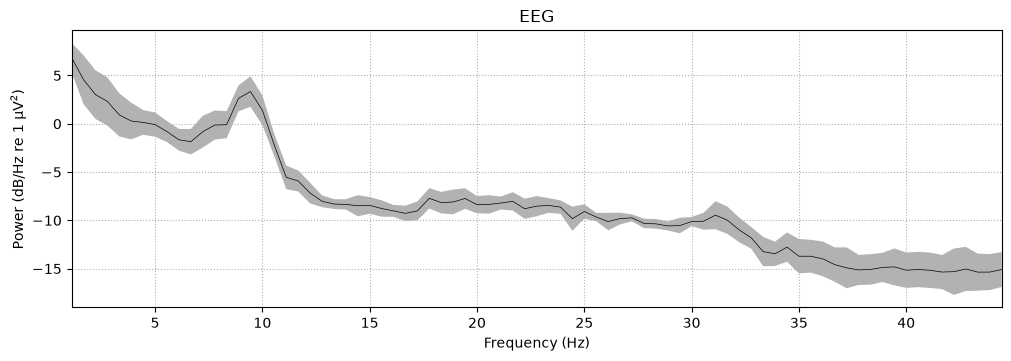

In [28]:

def calculate_psd(epochs):
    return epochs.compute_psd(
        method="welch",
        fmin=1,
        fmax=45,
        picks="eeg"
    )


post_psd = calculate_psd(post_epochs)
front_psd = calculate_psd(front_epochs)

print("Posterior PSD")
post_psd.plot(average=True, dB=True)

print("Frontal PSD")
front_psd.plot(average=True, dB=True)


Averaging across epochs before plotting...


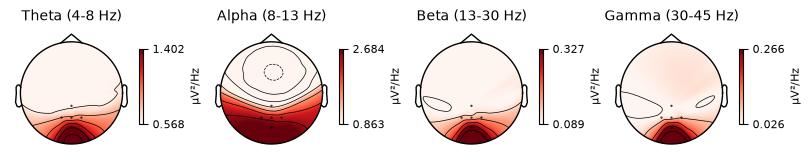

Averaging across epochs before plotting...


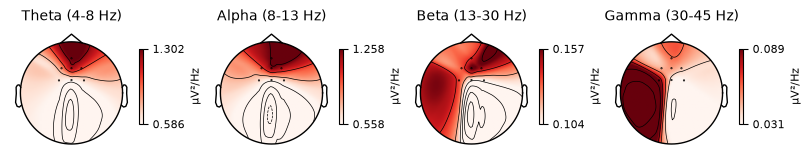

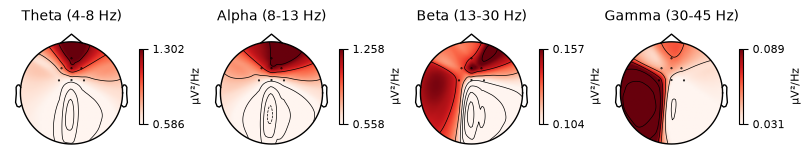

In [29]:

bands = {
    "Theta (4-8 Hz)": (4, 8),
    "Alpha (8-13 Hz)": (8, 13),
    "Beta (13-30 Hz)": (13, 30),
    "Gamma (30-45 Hz)": (30, 45),
}

post_psd.plot_topomap(
    bands=bands,
    ch_type="eeg"
)

front_psd.plot_topomap(
    bands=bands,
    ch_type="eeg"
)


Posterior time-frequency power
No baseline correction applied


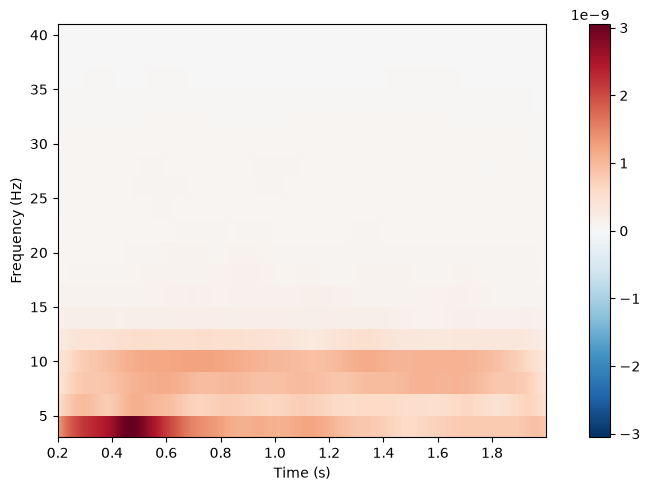

Frontal time-frequency power
No baseline correction applied


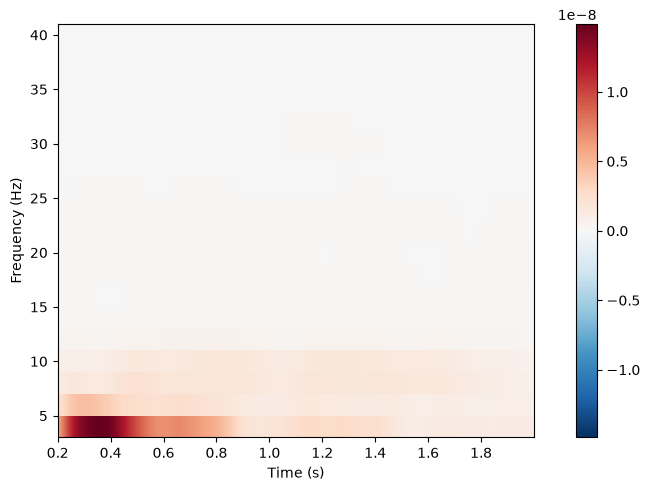

[<Figure size 640x480 with 2 Axes>]

In [30]:

freqs = np.arange(4, 41, 2)
n_cycles = freqs / 2


def calculate_time_frequency(epochs):
    return epochs.compute_tfr(
        method="morlet",
        freqs=freqs,
        n_cycles=n_cycles,
        average=True,
        return_itc=False,
        picks="eeg"
    )


post_power = calculate_time_frequency(post_epochs)
front_power = calculate_time_frequency(front_epochs)

post_channels = post_epochs.copy().pick("eeg").ch_names
front_channels = front_epochs.copy().pick("eeg").ch_names

print("Posterior time-frequency power")
post_power.plot(picks=[post_channels[0]])

print("Frontal time-frequency power")
front_power.plot(picks=[front_channels[0]])


/var/folders/rh/p5yby44s3_q7gw0x4t4155p40000gq/T/ipykernel_88310/441681883.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


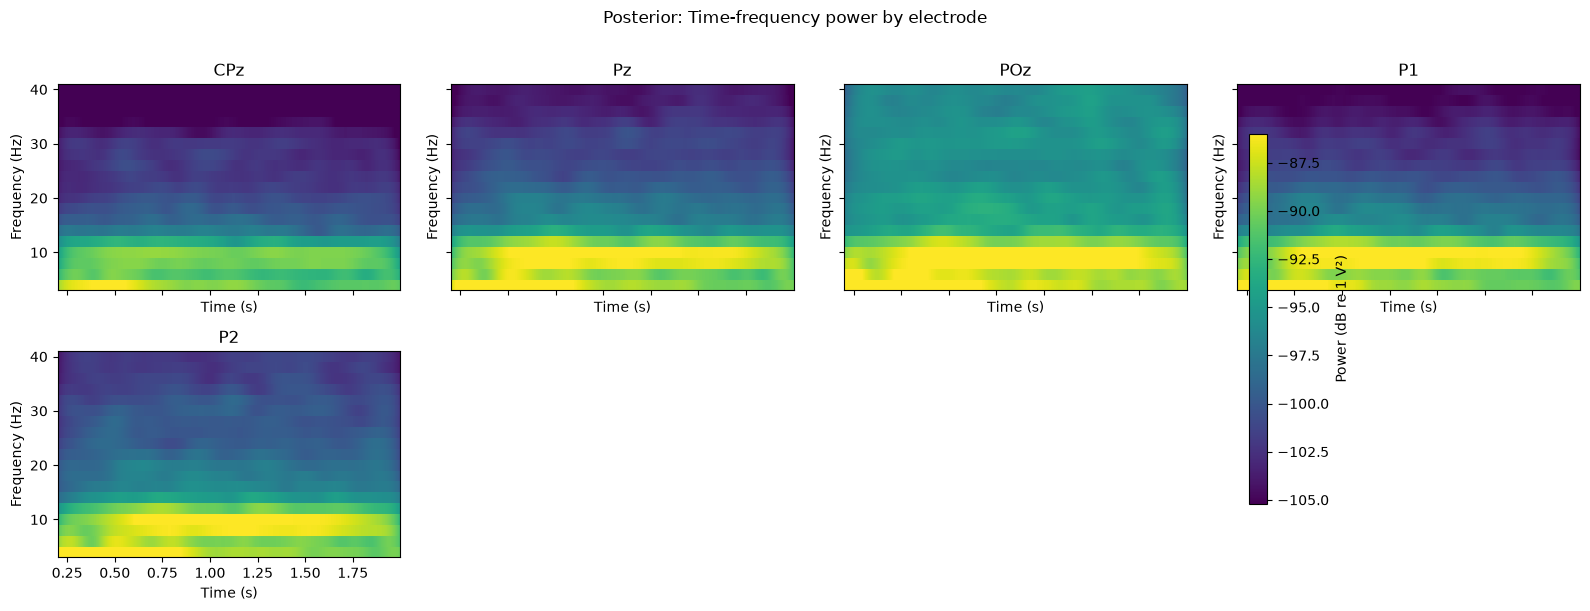

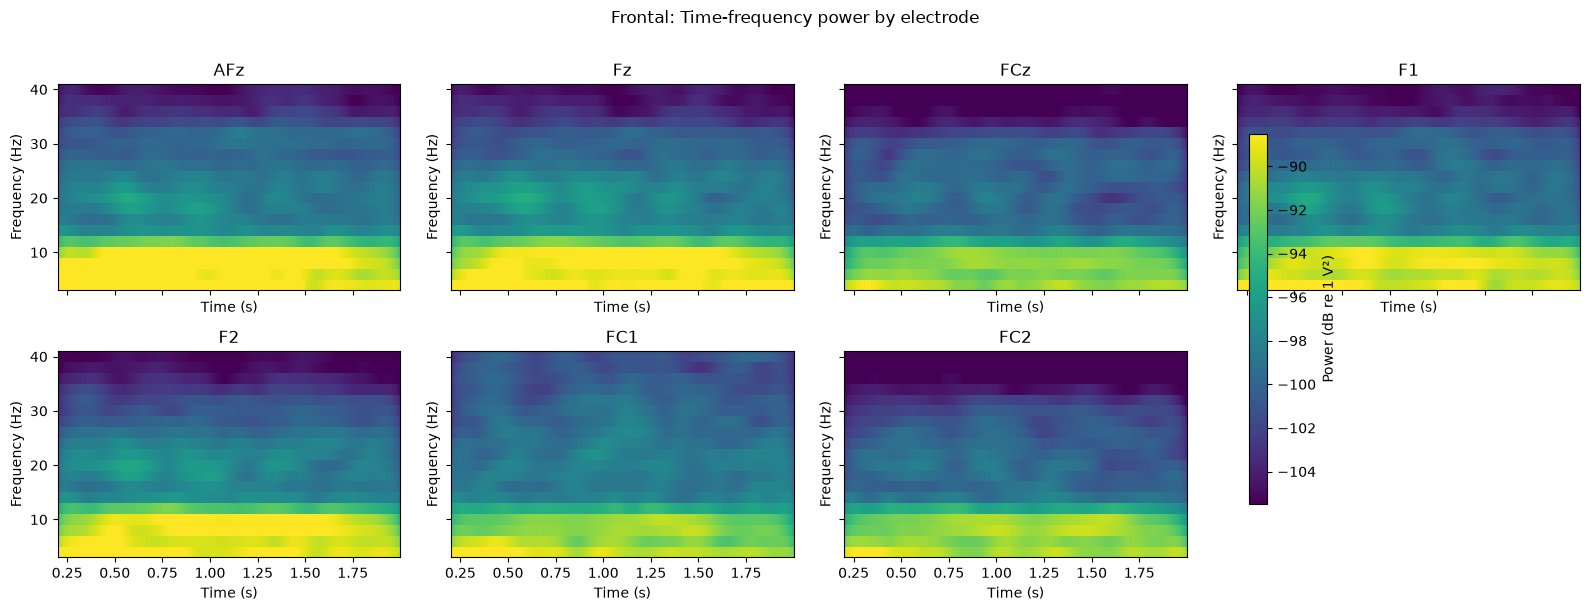

In [35]:

import numpy as np
import matplotlib.pyplot as plt

freqs = np.arange(4, 41, 2)
n_cycles = freqs / 2

def plot_all_electrodes(epochs, label):
    power = epochs.compute_tfr(
        method="morlet",
        freqs=freqs,
        n_cycles=n_cycles,
        average=True,
        return_itc=False,
        picks="eeg"
    )

    n_channels = len(power.ch_names)
    n_cols = 4
    n_rows = int(np.ceil(n_channels / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(16, 3 * n_rows),
        sharex=True,
        sharey=True,
        squeeze=False
    )

    # Ta sama skala kolorów dla wszystkich elektrod w danym zbiorze
    power_db = 10 * np.log10(
        np.maximum(power.data, np.finfo(float).tiny)
    )

    vmin = np.percentile(power_db, 5)
    vmax = np.percentile(power_db, 95)

    for i, ax in enumerate(axes.flat):
        if i >= n_channels:
            ax.set_visible(False)
            continue

        mesh = ax.pcolormesh(
            power.times,
            power.freqs,
            power_db[i],
            shading="auto",
            cmap="viridis",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(power.ch_names[i])
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Frequency (Hz)")

    fig.suptitle(f"{label}: Time-frequency power by electrode", y=1.01)
    fig.colorbar(mesh, ax=axes.ravel().tolist(),
                 label="Power (dB re 1 V²)", shrink=0.8)
    plt.tight_layout()
    plt.show()


plot_all_electrodes(post_epochs, "Posterior")
plot_all_electrodes(front_epochs, "Frontal")
